In [1]:
import io
import json
import os
import random
import re
import subprocess
import sys
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import sacrebleu
import sentencepiece as spm
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = "data"
MODEL_DIR = "models"
SPLIT_DIR = os.path.join(DATA_DIR, "splits")
OUT_DIR = "outputs"
for d in (DATA_DIR, MODEL_DIR, SPLIT_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

# OpenNMT-py 3.5.1 pins torch<2.3, which has no kernels for Blackwell GPUs (sm_120).  It is
# installed with `pip install --no-deps OpenNMT-py==3.5.1` on top of a CUDA 12.8 torch build
# and runs unchanged - see README for the exact install commands.
import warnings

with warnings.catch_warnings():                 # torch.cuda.amp deprecation notices
    warnings.simplefilter("ignore")
    import onmt

print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__, "| cuda:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
print("OpenNMT-py  :", onmt.__version__)
print("sacrebleu   :", sacrebleu.__version__)
print("sentencepiece:", spm.__version__)

python      : 3.11.9
torch       : 2.11.0+cu128 | cuda: True | NVIDIA GeForce RTX 5050 Laptop GPU
OpenNMT-py  : 3.5.1
sacrebleu   : 2.6.0
sentencepiece: 0.2.2


In [2]:
# ----------------------------- experiment configuration -----------------------------
CONFIG = {
    # ---- data: BPCC / ILCI subset, English -> Gujarati ---------------------------------
    "repo_id": "ai4bharat/BPCC",
    "ilci_file": "ilci/guj_Gujr.tsv",
    "src_lang": "en",
    "tgt_lang": "gu",

    # ---- length bins, on the number of whitespace tokens of the English source --------
    # The assignment gives bin2 = (10, 20) and bin3 = (20, 30) as open intervals, which
    # would leave length-20 sentences (4 267 of them) in no bin.  We close bin2 on the
    # right:  bin1 <= 10 | 10 < bin2 <= 20 | 20 < bin3 < 30 | bin4 >= 30.
    "bins": ["bin1", "bin2", "bin3", "bin4"],

    # ---- stratified splits: the same number of sentences from every bin ----------------
    # ---- cleaning: ILCI has misaligned pairs (an English sentence paired with a neighbouring
    # Gujarati one).  They show up as extreme word-count ratios and are far more common among
    # long sentences, so they would bias the bin-wise comparison.  Pairs whose English side has
    # >= `ratio_min_src_len` words and whose Gujarati/English word ratio is outside
    # [ratio_lo, ratio_hi] are dropped *before* splitting (very short sentences are exempt:
    # "What happened ?" -> "શું થયું ?" is a perfectly fine 1.5 ratio).
    "ratio_min_src_len": 6,
    "ratio_lo": 0.4,
    "ratio_hi": 2.5,

    "test_per_bin": 500,
    "dev_per_bin": 200,

    # ---- subword model (one SentencePiece unigram model per language) -----------------
    "spm_vocab_size": 8000,
    "spm_character_coverage": 1.0,

    # ---- Transformer (OpenNMT-py) ---------------------------------------------------
    "layers": 6,
    "hidden_size": 512,
    "word_vec_size": 512,
    "transformer_ff": 2048,
    "heads": 8,
    "dropout": 0.3,
    "attention_dropout": 0.1,
    "label_smoothing": 0.1,
    "batch_size": 4096,          # tokens per batch
    "accum_count": 2,            # -> ~8k tokens per update
    "learning_rate": 2.0,        # noam schedule
    "warmup_steps": 4000,
    "train_steps": 20000,         # ~46 epochs; early stopping usually ends it sooner
    "valid_steps": 1000,
    "save_checkpoint_steps": 1000,
    "keep_checkpoint": 5,
    "early_stopping": 5,         # validations without improvement in valid ppl

    # ---- decoding --------------------------------------------------------------------
    "beam_size": 5,
    "max_length": 300,           # subword tokens
}
SRC, TGT = CONFIG["src_lang"], CONFIG["tgt_lang"]
BINS = CONFIG["bins"]
print(json.dumps(CONFIG, indent=1))

{
 "repo_id": "ai4bharat/BPCC",
 "ilci_file": "ilci/guj_Gujr.tsv",
 "src_lang": "en",
 "tgt_lang": "gu",
 "bins": [
  "bin1",
  "bin2",
  "bin3",
  "bin4"
 ],
 "ratio_min_src_len": 6,
 "ratio_lo": 0.4,
 "ratio_hi": 2.5,
 "test_per_bin": 500,
 "dev_per_bin": 200,
 "spm_vocab_size": 8000,
 "spm_character_coverage": 1.0,
 "layers": 6,
 "hidden_size": 512,
 "word_vec_size": 512,
 "transformer_ff": 2048,
 "heads": 8,
 "dropout": 0.3,
 "attention_dropout": 0.1,
 "label_smoothing": 0.1,
 "batch_size": 4096,
 "accum_count": 2,
 "learning_rate": 2.0,
 "warmup_steps": 4000,
 "train_steps": 20000,
 "valid_steps": 1000,
 "save_checkpoint_steps": 1000,
 "keep_checkpoint": 5,
 "early_stopping": 5,
 "beam_size": 5,
 "max_length": 300
}


In [3]:
# The BPCC repository is gated (auto-approved): accept the terms on the dataset page, and use
# a token that can read gated repos (`hf auth login`).  The file is cached under data/.
from huggingface_hub import hf_hub_download

ILCI_PATH = os.path.join(DATA_DIR, CONFIG["ilci_file"])
if not os.path.exists(ILCI_PATH):
    hf_hub_download(CONFIG["repo_id"], CONFIG["ilci_file"], repo_type="dataset", local_dir=DATA_DIR)


def clean(text):
    return re.sub(r"\s+", " ", text).strip()


pairs = []
with io.open(ILCI_PATH, encoding="utf-8") as f:
    header = next(f).rstrip("\n").split("\t")           # src_lang tgt_lang src tgt
    for line in f:
        src_lang, tgt_lang, src, tgt = line.rstrip("\n").split("\t")
        assert (src_lang, tgt_lang) == ("eng_Latn", "guj_Gujr")
        src, tgt = clean(src), clean(tgt)
        if src and tgt:
            pairs.append((src, tgt))

n_raw = len(pairs)
pairs = list(dict.fromkeys(pairs))                      # drop exact duplicate pairs, keep order
n_unique = len(pairs)


def well_aligned(src, tgt):
    ns, nt = len(src.split()), len(tgt.split())
    return ns < CONFIG["ratio_min_src_len"] or CONFIG["ratio_lo"] <= nt / ns <= CONFIG["ratio_hi"]


dropped = [(s, t) for s, t in pairs if not well_aligned(s, t)]
pairs = [(s, t) for s, t in pairs if well_aligned(s, t)]
print("header         :", header)
print("pairs in file  :", n_raw)
print("unique pairs   :", n_unique)
print("ratio-filtered :", len(dropped), "->", len(pairs), "pairs kept")
for s, t in dropped[:3]:
    print("   dropped:", s[:90], "=>", t[:60])
for s, t in pairs[:3]:
    print("  ", s, "=>", t)

D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


header         : ['src_lang', 'tgt_lang', 'src', 'tgt']
pairs in file  : 107385
unique pairs   : 107385
ratio-filtered : 2489 -> 104896 pairs kept
   dropped: There is so much space in the courtyard of the temple that two thousand people can easily  => અને તેની આંતરિક સજાવટ ખૂબ લોભામણી છે .
   dropped: The train route going to Goa is full of small hills and valleys . => મંદિરના આંગણમાં એટલી જગ્યા છે
   dropped: The hypnotic waterfall of Tirathgarh located at distance of 35 kilometres from Jagdalpur h => કાંકેર ખીણપ્રદેશના મુખ્ય પર્યટનસ્થળ નીચે મુજબ છે
   What happened? => શું થયું ?
   What’s the matter? => શું વાત છે ?
   One gets Moksha with a visit to the Saptapuris ! => સપ્તપુરીઓના દર્શનથી મળે છે મોક્ષ .


In [4]:
def sent_len(src):
    """Sentence length = number of whitespace tokens of the English source."""
    return len(src.split())


def bin_of(n):
    if n <= 10:
        return "bin1"
    if n <= 20:
        return "bin2"
    if n < 30:
        return "bin3"
    return "bin4"


BIN_RANGE = {"bin1": "len <= 10", "bin2": "10 < len <= 20", "bin3": "20 < len < 30", "bin4": "len >= 30"}

by_bin = defaultdict(list)
for s, t in pairs:
    by_bin[bin_of(sent_len(s))].append((s, t))

src_lens = np.array([sent_len(s) for s, _ in pairs])
tgt_lens = np.array([len(t.split()) for _, t in pairs])
print(f"English length : mean {src_lens.mean():.1f}  median {np.median(src_lens):.0f}  "
      f"p95 {np.percentile(src_lens, 95):.0f}  max {src_lens.max()}")
print(f"Gujarati length: mean {tgt_lens.mean():.1f}  median {np.median(tgt_lens):.0f}  "
      f"p95 {np.percentile(tgt_lens, 95):.0f}  max {tgt_lens.max()}")
print(f"{'bin':6s} {'range':16s} {'pairs':>7s} {'share':>7s}")
for b in BINS:
    print(f"{b:6s} {BIN_RANGE[b]:16s} {len(by_bin[b]):7d} {len(by_bin[b]) / len(pairs):7.1%}")

English length : mean 17.8  median 16  p95 33  max 114
Gujarati length: mean 16.0  median 14  p95 30  max 108
bin    range              pairs   share
bin1   len <= 10          18857   18.0%
bin2   10 < len <= 20     53608   51.1%
bin3   20 < len < 30      23118   22.0%
bin4   len >= 30           9313    8.9%


In [5]:
# Length-stratified splits.  Inside every bin the pairs are shuffled and the first
# `test_per_bin` go to test, the next `dev_per_bin` to dev, the rest to train - so test and
# dev hold the same number of sentences of every length range, and train keeps all four bins
# in their natural proportions.
#
# ILCI has many repeated English sentences with different Gujarati renderings (and vice
# versa).  A train pair that shares its source *or* its target with a dev/test pair would leak
# the answer, so such pairs are removed from train.
rng = random.Random(SEED)
splits = {"train": defaultdict(list), "dev": defaultdict(list), "test": defaultdict(list)}
for b in BINS:
    items = by_bin[b][:]
    rng.shuffle(items)
    nt, nd = CONFIG["test_per_bin"], CONFIG["dev_per_bin"]
    splits["test"][b] = items[:nt]
    splits["dev"][b] = items[nt:nt + nd]
    splits["train"][b] = items[nt + nd:]

held_src = {s for sp in ("dev", "test") for b in BINS for s, _ in splits[sp][b]}
held_tgt = {t for sp in ("dev", "test") for b in BINS for _, t in splits[sp][b]}
n_leak = 0
for b in BINS:
    kept = [(s, t) for s, t in splits["train"][b] if s not in held_src and t not in held_tgt]
    n_leak += len(splits["train"][b]) - len(kept)
    splits["train"][b] = kept
print("train pairs removed for overlapping with dev/test:", n_leak)


def write_lines(path, lines):
    with io.open(path, "w", encoding="utf-8", newline="\n") as f:
        for line in lines:
            f.write(line + "\n")


for sp in ("train", "dev", "test"):
    allpairs = [p for b in BINS for p in splits[sp][b]]
    if sp == "train":
        rng.shuffle(allpairs)                       # don't train on bin-sorted data
    write_lines(os.path.join(SPLIT_DIR, f"{sp}.{SRC}"), [s for s, _ in allpairs])
    write_lines(os.path.join(SPLIT_DIR, f"{sp}.{TGT}"), [t for _, t in allpairs])
    for b in BINS:
        write_lines(os.path.join(SPLIT_DIR, f"{sp}.{b}.{SRC}"), [s for s, _ in splits[sp][b]])
        write_lines(os.path.join(SPLIT_DIR, f"{sp}.{b}.{TGT}"), [t for _, t in splits[sp][b]])

print(f"\n{'split':6s} " + " ".join(f"{b:>7s}" for b in BINS) + f" {'total':>8s}")
for sp in ("train", "dev", "test"):
    counts = [len(splits[sp][b]) for b in BINS]
    print(f"{sp:6s} " + " ".join(f"{c:7d}" for c in counts) + f" {sum(counts):8d}")

train pairs removed for overlapping with dev/test: 420



split     bin1    bin2    bin3    bin4    total
train    18027   52783   22314    8552   101676
dev        200     200     200     200      800
test       500     500     500     500     2000


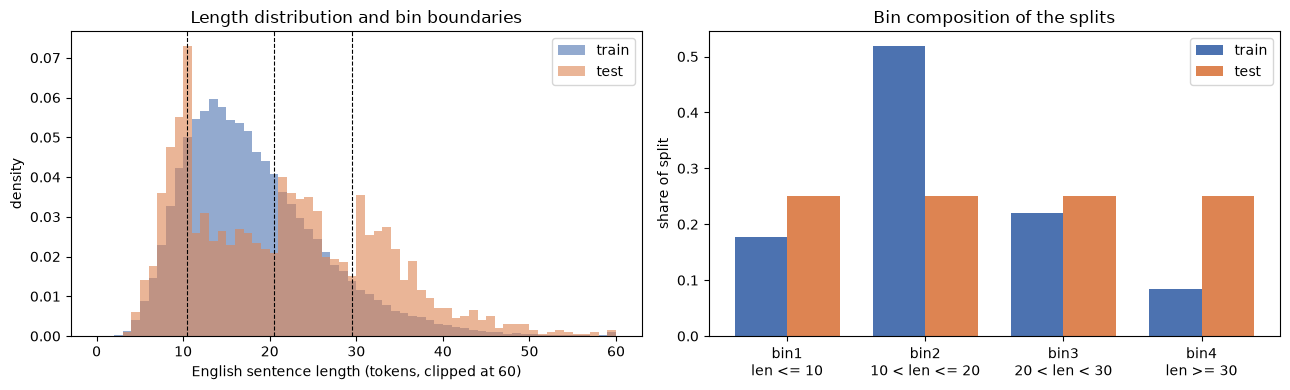

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
edges = np.arange(0, 61, 1)
colors = {"train": "#4C72B0", "test": "#DD8452"}
for sp in ("train", "test"):
    lens = [sent_len(s) for b in BINS for s, _ in splits[sp][b]]
    axes[0].hist(np.clip(lens, 0, 60), bins=edges, density=True, alpha=0.6, label=sp, color=colors[sp])
for x in (10.5, 20.5, 29.5):
    axes[0].axvline(x, color="k", ls="--", lw=0.8)
axes[0].set_xlabel("English sentence length (tokens, clipped at 60)")
axes[0].set_ylabel("density")
axes[0].set_title("Length distribution and bin boundaries")
axes[0].legend()

x = np.arange(len(BINS))
w = 0.38
tr = [len(splits["train"][b]) for b in BINS]
te = [len(splits["test"][b]) for b in BINS]
axes[1].bar(x - w / 2, np.array(tr) / sum(tr), w, label="train", color=colors["train"])
axes[1].bar(x + w / 2, np.array(te) / sum(te), w, label="test", color=colors["test"])
axes[1].set_xticks(x, [f"{b}\n{BIN_RANGE[b]}" for b in BINS])
axes[1].set_ylabel("share of split")
axes[1].set_title("Bin composition of the splits")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "length_bins.png"), dpi=120)
plt.show()

In [7]:
# Subword segmentation: one SentencePiece unigram model per language, trained on the training
# split only.  OpenNMT-py applies them on the fly through its `sentencepiece` transform.
SPM_PREFIX = {lang: os.path.join(MODEL_DIR, f"spm.{lang}") for lang in (SRC, TGT)}
for lang in (SRC, TGT):
    if not os.path.exists(SPM_PREFIX[lang] + ".model"):
        spm.SentencePieceTrainer.train(
            input=os.path.join(SPLIT_DIR, f"train.{lang}"),
            model_prefix=SPM_PREFIX[lang],
            vocab_size=CONFIG["spm_vocab_size"],
            model_type="unigram",
            character_coverage=CONFIG["spm_character_coverage"],
            input_sentence_size=2_000_000,
            shuffle_input_sentence=True,
            seed_sentencepiece_size=1_000_000,
            minloglevel=2,
        )
SP = {lang: spm.SentencePieceProcessor(model_file=SPM_PREFIX[lang] + ".model") for lang in (SRC, TGT)}

for lang in (SRC, TGT):
    with io.open(os.path.join(SPLIT_DIR, f"train.{lang}"), encoding="utf-8") as f:
        sample = [next(f).rstrip("\n") for _ in range(2000)]
    n_words = sum(len(s.split()) for s in sample)
    n_pieces = sum(len(SP[lang].encode(s)) for s in sample)
    print(f"[{lang}] vocab {SP[lang].get_piece_size()}  pieces/word {n_pieces / n_words:.2f}  e.g.",
          SP[lang].encode(sample[0], out_type=str)[:14])

[en] vocab 8000  pieces/word 1.26  e.g. ['▁Sa', 'y', 'ing', '▁this', '▁would', '▁not', '▁be', '▁irrelevant', '▁in', '▁this', '▁context', '▁that', '▁importance', '▁of']
[gu] vocab 8000  pieces/word 1.40  e.g. ['▁આ', '▁પ્રસંગે', '▁એ', '▁કહેવું', '▁અપ', '્રા', 'સ', 'ંગ', 'િક', '▁નહીં', '▁ગણાય', '▁કે', '▁એ', '▁દિવસોમાં']


In [8]:
# OpenNMT-py configuration.  Paths are relative to this notebook's directory.
RUN_DIR = os.path.join(MODEL_DIR, "en_gu_transformer")
os.makedirs(RUN_DIR, exist_ok=True)
CFG_PATH = os.path.join(RUN_DIR, "config.yaml")
p = lambda *parts: os.path.join(*parts).replace("\\", "/")

onmt_cfg = f"""
save_data: {p(RUN_DIR, "data")}
src_vocab: {p(RUN_DIR, "vocab.src")}
tgt_vocab: {p(RUN_DIR, "vocab.tgt")}
overwrite: true
seed: {SEED}

data:
    corpus_1:
        path_src: {p(SPLIT_DIR, "train." + SRC)}
        path_tgt: {p(SPLIT_DIR, "train." + TGT)}
        transforms: [sentencepiece, filtertoolong]
    valid:
        path_src: {p(SPLIT_DIR, "dev." + SRC)}
        path_tgt: {p(SPLIT_DIR, "dev." + TGT)}
        transforms: [sentencepiece]

src_subword_model: {p(SPM_PREFIX[SRC] + ".model")}
tgt_subword_model: {p(SPM_PREFIX[TGT] + ".model")}
src_seq_length: 200
tgt_seq_length: 200
src_words_min_frequency: 1
tgt_words_min_frequency: 1

# ---- model ----
encoder_type: transformer
decoder_type: transformer
position_encoding: true
layers: {CONFIG["layers"]}
hidden_size: {CONFIG["hidden_size"]}
word_vec_size: {CONFIG["word_vec_size"]}
transformer_ff: {CONFIG["transformer_ff"]}
heads: {CONFIG["heads"]}
dropout: [{CONFIG["dropout"]}]
attention_dropout: [{CONFIG["attention_dropout"]}]
param_init: 0.0
param_init_glorot: true
label_smoothing: {CONFIG["label_smoothing"]}

# ---- optimisation ----
model_dtype: fp16
optim: adam
adam_beta1: 0.9
adam_beta2: 0.998
learning_rate: {CONFIG["learning_rate"]}
decay_method: noam
warmup_steps: {CONFIG["warmup_steps"]}
max_grad_norm: 0.0
batch_type: tokens
batch_size: {CONFIG["batch_size"]}
valid_batch_size: 2048
accum_count: [{CONFIG["accum_count"]}]
accum_steps: [0]
normalization: tokens
bucket_size: 32768
num_workers: 0
train_steps: {CONFIG["train_steps"]}
valid_steps: {CONFIG["valid_steps"]}
early_stopping: {CONFIG["early_stopping"]}
early_stopping_criteria: ppl
save_model: {p(RUN_DIR, "model")}
save_checkpoint_steps: {CONFIG["save_checkpoint_steps"]}
keep_checkpoint: {CONFIG["keep_checkpoint"]}
report_every: 100
log_file: {p(RUN_DIR, "train.log")}
world_size: 1
gpu_ranks: [0]
"""
with io.open(CFG_PATH, "w", encoding="utf-8", newline="\n") as f:
    f.write(onmt_cfg.lstrip())
print(onmt_cfg)


save_data: models/en_gu_transformer/data
src_vocab: models/en_gu_transformer/vocab.src
tgt_vocab: models/en_gu_transformer/vocab.tgt
overwrite: true
seed: 42

data:
    corpus_1:
        path_src: data/splits/train.en
        path_tgt: data/splits/train.gu
        transforms: [sentencepiece, filtertoolong]
    valid:
        path_src: data/splits/dev.en
        path_tgt: data/splits/dev.gu
        transforms: [sentencepiece]

src_subword_model: models/spm.en.model
tgt_subword_model: models/spm.gu.model
src_seq_length: 200
tgt_seq_length: 200
src_words_min_frequency: 1
tgt_words_min_frequency: 1

# ---- model ----
encoder_type: transformer
decoder_type: transformer
position_encoding: true
layers: 6
hidden_size: 512
word_vec_size: 512
transformer_ff: 2048
heads: 8
dropout: [0.3]
attention_dropout: [0.1]
param_init: 0.0
param_init_glorot: true
label_smoothing: 0.1

# ---- optimisation ----
model_dtype: fp16
optim: adam
adam_beta1: 0.9
adam_beta2: 0.998
learning_rate: 2.0
decay_method: no

In [9]:
def run(args, log_path=None, echo_every=1):
    """Run an OpenNMT-py entry point (`python -m onmt.bin.<tool>`), streaming its output."""
    cmd = [sys.executable, "-m"] + args
    print(">>", " ".join(cmd))
    t0 = time.time()
    # torch >= 2.6 defaults torch.load(weights_only=True), which rejects OpenNMT-py checkpoints
    # (they pickle the argparse.Namespace of options).  These are our own checkpoints.
    env = dict(os.environ, PYTHONUTF8="1", PYTHONIOENCODING="utf-8", PYTHONWARNINGS="ignore",
               TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD="1")
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, encoding="utf-8", errors="replace", env=env)
    lines = []
    for i, line in enumerate(proc.stdout):
        lines.append(line.rstrip("\n"))
        if echo_every and i % echo_every == 0:
            print(line, end="")
    proc.wait()
    if log_path:
        write_lines(log_path, lines)
    print(f"[exit {proc.returncode} after {time.time() - t0:.0f}s]")
    if proc.returncode != 0:
        print("\n".join(lines[-30:]))
        raise RuntimeError(f"{args[0]} failed")
    return lines


# vocabularies are built over the SentencePiece-segmented training data
run(["onmt.bin.build_vocab", "-config", CFG_PATH, "-n_sample", "-1"], echo_every=0)

# Windows fix: build_vocab writes the vocab in text mode (CRLF line ends), but the trainer splits
# the file on b"\n" only.  Every count then ends in "\r" ("98155\r".isdigit() is False), so the
# "token<TAB>count" lines are taken verbatim as tokens and *every* real token becomes <unk>
# (training "converges" to ~96 % accuracy by predicting <unk>).  Rewriting with LF fixes it.
for side in ("src", "tgt"):
    path = os.path.join(RUN_DIR, f"vocab.{side}")
    with open(path, "rb") as f:
        raw = f.read()
    with open(path, "wb") as f:
        f.write(raw.replace(b"\r\n", b"\n"))
    with io.open(path, encoding="utf-8") as f:
        entries = [line.rstrip("\n").split("\t") for line in f]
    print(f"vocab.{side}: {len(entries)} entries, top 8:", [e[0] for e in entries[:8]])

>> D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Scripts\python.exe -m onmt.bin.build_vocab -config models\en_gu_transformer\config.yaml -n_sample -1


[exit 0 after 22s]
vocab.src: 7997 entries, top 8: ['▁the', '▁of', '▁.', 's', '▁and', '▁in', '▁is', '.']
vocab.tgt: 7994 entries, top 8: ['▁છે', '▁.', '.', 'ની', '▁અને', 'ના', 'માં', '▁,']


In [10]:
# Training.  Skipped if a finished run is already on disk (delete models/en_gu_transformer/
# to retrain).  The full stdout of the trainer (step reports, validation) is kept in
# train_stdout.log; only every 2000th step and the validation lines are echoed here.
DONE_FLAG = os.path.join(RUN_DIR, "TRAINING_DONE")
TRAIN_STDOUT = os.path.join(RUN_DIR, "train_stdout.log")    # step reports only reach stdout
if not os.path.exists(DONE_FLAG):
    for ckpt in [f for f in os.listdir(RUN_DIR) if f.startswith("model_step_")]:
        os.remove(os.path.join(RUN_DIR, ckpt))
    run(["onmt.bin.train", "-config", CFG_PATH], log_path=TRAIN_STDOUT, echo_every=0)
    with open(DONE_FLAG, "w") as f:
        f.write("done\n")

stamps = []
with io.open(TRAIN_STDOUT, encoding="utf-8", errors="replace") as f:
    for line in f:
        line = line.rstrip("\n")
        m = re.match(r"\[(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d)", line)
        if m:
            stamps.append(time.mktime(time.strptime(m.group(1), "%Y-%m-%d %H:%M:%S")))
        if re.search(r"Step \d+/|Validation|early|number of parameters|encoder:|decoder:", line, re.I):
            if "Step " in line and int(re.search(r"Step (\d+)", line).group(1)) % 2000:
                continue
            print(line)
print(f"\ntraining wall time: {(stamps[-1] - stamps[0]) / 60:.0f} min")
print(sorted(f for f in os.listdir(RUN_DIR) if f.endswith(".pt")))

[2026-10-01 13:28:23,327 INFO] encoder: 22987776
[2026-10-01 13:28:23,327 INFO] decoder: 33385280
[2026-10-01 13:28:23,327 INFO] * number of parameters: 56373056
[2026-10-01 13:42:17,730 INFO] Validation perplexity: 385.083
[2026-10-01 13:42:17,730 INFO] Validation accuracy: 18.6016
[2026-10-01 13:46:56,293 INFO] Step 2000/20000; acc: 28.5; ppl: 148.0; xent: 5.0; lr: 0.00070; sents:   26942; bsz: 2989/3099/135; 21797/22598 tok/s;   1113 sec;
[2026-10-01 13:46:56,876 INFO] Validation perplexity: 162.363
[2026-10-01 13:46:56,876 INFO] Validation accuracy: 27.6285
[2026-10-01 13:51:30,235 INFO] Validation perplexity: 109.775
[2026-10-01 13:51:30,235 INFO] Validation accuracy: 33.3648
[2026-10-01 13:56:01,499 INFO] Step 4000/20000; acc: 39.6; ppl:  62.5; xent: 4.1; lr: 0.00140; sents:   27424; bsz: 2986/3067/137; 21642/22228 tok/s;   1658 sec;
[2026-10-01 13:56:02,072 INFO] Validation perplexity: 82.4471
[2026-10-01 13:56:02,072 INFO] Validation accuracy: 37.3778
[2026-10-01 14:00:34,150 I

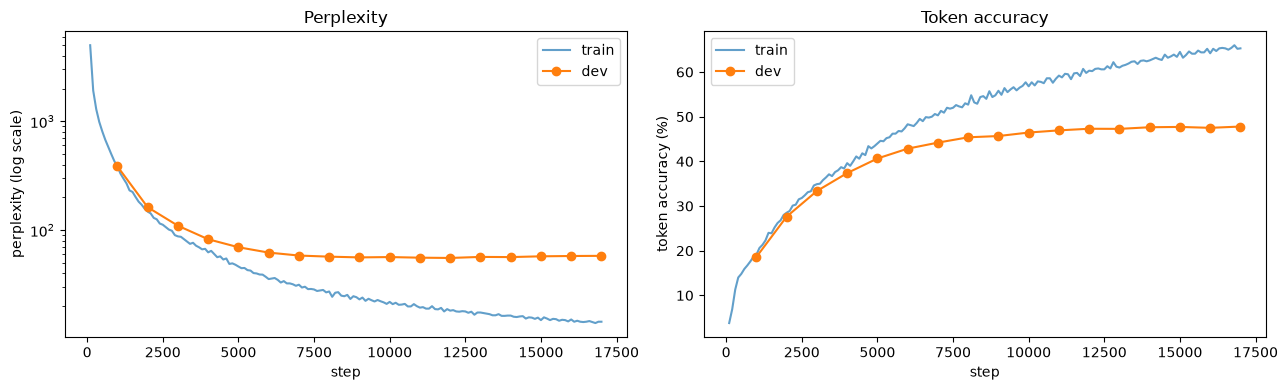

best dev ppl 55.50 at step 12000
dev ppl by step: 1000:385.08, 2000:162.36, 3000:109.78, 4000:82.45, 5000:69.62, 6000:62.17, 7000:58.40, 8000:57.04, 9000:56.15, 10000:56.56, 11000:55.82, 12000:55.50, 13000:56.74, 14000:56.52, 15000:57.46, 16000:57.84, 17000:58.03


In [11]:
# Training curves, parsed from the OpenNMT-py log.
step_re = re.compile(r"Step (\d+)/\s*\d+; acc:\s*([\d.]+); ppl:\s*([\d.]+)")
val_ppl_re = re.compile(r"Validation perplexity: ([\d.]+)")
val_acc_re = re.compile(r"Validation accuracy: ([\d.]+)")
train_curve, val_ppl, val_acc = [], [], []
with io.open(TRAIN_STDOUT, encoding="utf-8", errors="replace") as f:
    last_step = 0
    for line in f:
        m = step_re.search(line)
        if m:
            last_step = int(m.group(1))
            train_curve.append((last_step, float(m.group(2)), float(m.group(3))))
        m = val_ppl_re.search(line)
        if m:
            val_ppl.append((last_step, float(m.group(1))))
        m = val_acc_re.search(line)
        if m:
            val_acc.append((last_step, float(m.group(1))))

train_curve = np.array(train_curve)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(train_curve[:, 0], train_curve[:, 2], label="train", alpha=0.7)
axes[0].plot(*zip(*val_ppl), "o-", label="dev")
axes[0].set_yscale("log")
axes[0].set_xlabel("step")
axes[0].set_ylabel("perplexity (log scale)")
axes[0].legend()
axes[0].set_title("Perplexity")
axes[1].plot(train_curve[:, 0], train_curve[:, 1], label="train", alpha=0.7)
axes[1].plot(*zip(*val_acc), "o-", label="dev")
axes[1].set_xlabel("step")
axes[1].set_ylabel("token accuracy (%)")
axes[1].legend()
axes[1].set_title("Token accuracy")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=120)
plt.show()

best_step, best_ppl = min(val_ppl, key=lambda x: x[1])
print(f"best dev ppl {best_ppl:.2f} at step {best_step}")
print("dev ppl by step:", ", ".join(f"{s}:{v:.2f}" for s, v in val_ppl))

In [12]:
# The checkpoint used for testing is chosen on the *dev* set only:  the single checkpoint with
# the lowest dev perplexity, and the average of the last `keep_checkpoint` checkpoints.  Both
# are scored by dev BLEU and the better one is used for the test set.
ckpts = sorted((f for f in os.listdir(RUN_DIR) if re.match(r"model_step_\d+\.pt$", f)),
               key=lambda f: int(re.search(r"(\d+)", f).group(1)))
print("kept checkpoints:", ckpts)
AVG_PATH = os.path.join(RUN_DIR, "model_avg.pt")
if not os.path.exists(AVG_PATH):
    run(["onmt.bin.average_models", "-models"] + [os.path.join(RUN_DIR, c) for c in ckpts]
        + ["-output", AVG_PATH], echo_every=0)

# keep_checkpoint only keeps the *last* checkpoints, so when early stopping fires the best one
# has usually been pruned.  A copy of it (best_step_<N>.pt) was taken during training; if it is
# missing too, only the averaged model is evaluated.
CANDIDATES = {"avg_last_ckpts": AVG_PATH}
for name in (f"model_step_{best_step}.pt", f"best_step_{best_step}.pt"):
    if os.path.exists(os.path.join(RUN_DIR, name)):
        CANDIDATES["best_dev_ppl"] = os.path.join(RUN_DIR, name)
print(CANDIDATES)

kept checkpoints: ['model_step_13000.pt', 'model_step_14000.pt', 'model_step_15000.pt', 'model_step_16000.pt', 'model_step_17000.pt']
>> D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Scripts\python.exe -m onmt.bin.average_models -models models\en_gu_transformer\model_step_13000.pt models\en_gu_transformer\model_step_14000.pt models\en_gu_transformer\model_step_15000.pt models\en_gu_transformer\model_step_16000.pt models\en_gu_transformer\model_step_17000.pt -output models\en_gu_transformer\model_avg.pt


[exit 0 after 10s]
{'avg_last_ckpts': 'models\\en_gu_transformer\\model_avg.pt', 'best_dev_ppl': 'models\\en_gu_transformer\\best_step_12000.pt'}


In [13]:
def read_lines(path):
    with io.open(path, encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f]


def translate(model_path, src_sentences, tag):
    """SentencePiece-encode, translate with onmt.bin.translate, SentencePiece-decode."""
    sp_src = os.path.join(OUT_DIR, f"{tag}.sp.{SRC}")
    sp_hyp = os.path.join(OUT_DIR, f"{tag}.sp.hyp.{TGT}")
    write_lines(sp_src, [" ".join(SP[SRC].encode(s, out_type=str)) for s in src_sentences])
    run(["onmt.bin.translate", "-model", model_path, "-src", sp_src, "-output", sp_hyp,
         "-gpu", "0", "-beam_size", str(CONFIG["beam_size"]), "-max_length", str(CONFIG["max_length"]),
         "-batch_size", "4096", "-batch_type", "tokens", "-replace_unk"], echo_every=0)
    hyps = [SP[TGT].decode(line.split()) for line in read_lines(sp_hyp)]
    assert len(hyps) == len(src_sentences)
    return hyps


dev_src = read_lines(os.path.join(SPLIT_DIR, f"dev.{SRC}"))
dev_ref = read_lines(os.path.join(SPLIT_DIR, f"dev.{TGT}"))
dev_scores = {}
for name, path in CANDIDATES.items():
    hyp = translate(path, dev_src, f"dev.{name}")
    dev_scores[name] = sacrebleu.corpus_bleu(hyp, [dev_ref], force=True).score
    print(f"dev BLEU  {name:15s} {dev_scores[name]:.2f}")
CHOSEN = max(dev_scores, key=dev_scores.get)
MODEL_PATH = CANDIDATES[CHOSEN]
print("-> test model:", CHOSEN, MODEL_PATH)

>> D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Scripts\python.exe -m onmt.bin.translate -model models\en_gu_transformer\model_avg.pt -src outputs\dev.avg_last_ckpts.sp.en -output outputs\dev.avg_last_ckpts.sp.hyp.gu -gpu 0 -beam_size 5 -max_length 300 -batch_size 4096 -batch_type tokens -replace_unk


[exit 0 after 19s]
dev BLEU  avg_last_ckpts  15.82
>> D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Scripts\python.exe -m onmt.bin.translate -model models\en_gu_transformer\best_step_12000.pt -src outputs\dev.best_dev_ppl.sp.en -output outputs\dev.best_dev_ppl.sp.hyp.gu -gpu 0 -beam_size 5 -max_length 300 -batch_size 4096 -batch_type tokens -replace_unk


[exit 0 after 19s]
dev BLEU  best_dev_ppl    15.16
-> test model: avg_last_ckpts models\en_gu_transformer\model_avg.pt


In [14]:
# Translate every test bin with the chosen model.
test = {}
for b in BINS:
    src = read_lines(os.path.join(SPLIT_DIR, f"test.{b}.{SRC}"))
    ref = read_lines(os.path.join(SPLIT_DIR, f"test.{b}.{TGT}"))
    hyp = translate(MODEL_PATH, src, f"test.{b}")
    write_lines(os.path.join(OUT_DIR, f"test.{b}.hyp.{TGT}"), hyp)
    test[b] = {"src": src, "ref": ref, "hyp": hyp}
    print(b, len(hyp), "translations")

>> D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Scripts\python.exe -m onmt.bin.translate -model models\en_gu_transformer\model_avg.pt -src outputs\test.bin1.sp.en -output outputs\test.bin1.sp.hyp.gu -gpu 0 -beam_size 5 -max_length 300 -batch_size 4096 -batch_type tokens -replace_unk


[exit 0 after 15s]
bin1 500 translations
>> D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Scripts\python.exe -m onmt.bin.translate -model models\en_gu_transformer\model_avg.pt -src outputs\test.bin2.sp.en -output outputs\test.bin2.sp.hyp.gu -gpu 0 -beam_size 5 -max_length 300 -batch_size 4096 -batch_type tokens -replace_unk


[exit 0 after 15s]
bin2 500 translations
>> D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Scripts\python.exe -m onmt.bin.translate -model models\en_gu_transformer\model_avg.pt -src outputs\test.bin3.sp.en -output outputs\test.bin3.sp.hyp.gu -gpu 0 -beam_size 5 -max_length 300 -batch_size 4096 -batch_type tokens -replace_unk


[exit 0 after 16s]
bin3 500 translations
>> D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Scripts\python.exe -m onmt.bin.translate -model models\en_gu_transformer\model_avg.pt -src outputs\test.bin4.sp.en -output outputs\test.bin4.sp.hyp.gu -gpu 0 -beam_size 5 -max_length 300 -batch_size 4096 -batch_type tokens -replace_unk


[exit 0 after 19s]
bin4 500 translations


In [15]:
# Bin-wise BLEU with sacrebleu (default 13a tokenisation, exponential smoothing off for corpus
# BLEU), plus chrF++ as a character-level cross-check that is kinder to Gujarati morphology.
# force=True: ILCI references are themselves tokenised ("... છે ."), which sacrebleu would
# otherwise warn about on every call.  Hypotheses follow the same convention.
bleu_metric = sacrebleu.metrics.BLEU(force=True)
sent_bleu_metric = sacrebleu.metrics.BLEU(effective_order=True, force=True)
chrf_metric = sacrebleu.metrics.CHRF(word_order=2)

rows = {}
for b in BINS + ["all"]:
    if b == "all":
        hyp = [h for bb in BINS for h in test[bb]["hyp"]]
        ref = [r for bb in BINS for r in test[bb]["ref"]]
    else:
        hyp, ref = test[b]["hyp"], test[b]["ref"]
    bleu = bleu_metric.corpus_score(hyp, [ref])
    chrf = chrf_metric.corpus_score(hyp, [ref])
    rows[b] = {"n": len(hyp), "bleu": bleu.score, "precisions": bleu.precisions, "bp": bleu.bp,
               "sys_len": bleu.sys_len, "ref_len": bleu.ref_len, "chrf": chrf.score,
               "signature": str(bleu_metric.get_signature())}

print(f"{'bin':5s} {'range':16s} {'n':>5s} {'BLEU':>6s} {'chrF++':>7s}   "
      f"{'p1':>5s} {'p2':>5s} {'p3':>5s} {'p4':>5s} {'BP':>6s} {'hyp/ref':>8s}")
for b, r in rows.items():
    print(f"{b:5s} {BIN_RANGE.get(b, 'all lengths'):16s} {r['n']:5d} {r['bleu']:6.2f} {r['chrf']:7.2f}   "
          + " ".join(f"{p:5.1f}" for p in r["precisions"])
          + f" {r['bp']:6.3f} {r['sys_len'] / r['ref_len']:8.3f}")
print("\nsacrebleu signature:", rows["all"]["signature"])

bin   range                n   BLEU  chrF++      p1    p2    p3    p4     BP  hyp/ref
bin1  len <= 10          500  22.45   40.76    55.0  32.5  19.3  13.0  0.868    0.876
bin2  10 < len <= 20     500  17.09   38.77    48.6  25.3  13.7   8.2  0.886    0.892
bin3  20 < len < 30      500  14.08   36.80    45.0  21.3  10.7   5.7  0.904    0.908
bin4  len >= 30          500  14.16   37.08    44.8  21.1  10.7   5.8  0.910    0.914
all   all lengths       2000  15.60   37.74    46.8  23.2  12.2   6.9  0.899    0.903

sacrebleu signature: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0


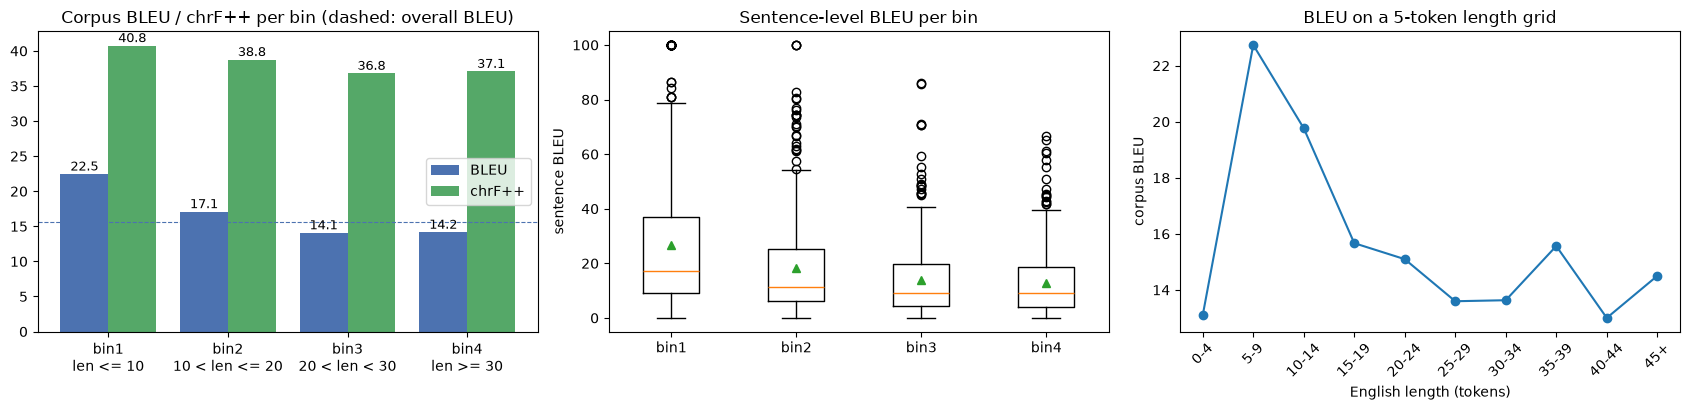

bin1: sentence BLEU mean  26.9  median  17.2  exact matches 5.8%  sentence BLEU = 0: 0.4%
bin2: sentence BLEU mean  18.4  median  11.5  exact matches 0.6%  sentence BLEU = 0: 0.2%
bin3: sentence BLEU mean  14.0  median   9.1  exact matches 0.0%  sentence BLEU = 0: 0.4%
bin4: sentence BLEU mean  13.0  median   9.1  exact matches 0.0%  sentence BLEU = 0: 0.2%
fine grid: 0-4: 13.1 (n=14), 5-9: 22.7 (n=340), 10-14: 19.8 (n=361), 15-19: 15.7 (n=243), 20-24: 15.1 (n=333), 25-29: 13.6 (n=209), 30-34: 13.6 (n=274), 35-39: 15.6 (n=122), 40-44: 13.0 (n=54), 45+: 14.5 (n=50)


In [16]:
# Sentence-level view: distribution of sentence BLEU per bin, and corpus BLEU on a finer length
# grid to see whether the bin trend is smooth.
sent_bleu = {b: np.array([sent_bleu_metric.sentence_score(h, [r]).score
                          for h, r in zip(test[b]["hyp"], test[b]["ref"])]) for b in BINS}

fine = defaultdict(lambda: ([], []))
for b in BINS:
    for s, h, r in zip(test[b]["src"], test[b]["hyp"], test[b]["ref"]):
        n = sent_len(s)
        key = min(n // 5 * 5, 45)
        fine[key][0].append(h)
        fine[key][1].append(r)
fine_keys = sorted(fine)
fine_bleu = [bleu_metric.corpus_score(fine[k][0], [fine[k][1]]).score for k in fine_keys]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
x = np.arange(len(BINS))
axes[0].bar(x - 0.2, [rows[b]["bleu"] for b in BINS], 0.4, label="BLEU", color="#4C72B0")
axes[0].bar(x + 0.2, [rows[b]["chrf"] for b in BINS], 0.4, label="chrF++", color="#55A868")
for i, b in enumerate(BINS):
    axes[0].text(i - 0.2, rows[b]["bleu"] + 0.5, f"{rows[b]['bleu']:.1f}", ha="center", fontsize=9)
    axes[0].text(i + 0.2, rows[b]["chrf"] + 0.5, f"{rows[b]['chrf']:.1f}", ha="center", fontsize=9)
axes[0].axhline(rows["all"]["bleu"], color="#4C72B0", ls="--", lw=0.8)
axes[0].set_xticks(x, [f"{b}\n{BIN_RANGE[b]}" for b in BINS])
axes[0].set_title("Corpus BLEU / chrF++ per bin (dashed: overall BLEU)")
axes[0].legend()

axes[1].boxplot([sent_bleu[b] for b in BINS], showmeans=True)
axes[1].set_xticks(x + 1, BINS)
axes[1].set_ylabel("sentence BLEU")
axes[1].set_title("Sentence-level BLEU per bin")

labels = [f"{k}-{k + 4}" if k < 45 else "45+" for k in fine_keys]
axes[2].plot(range(len(fine_keys)), fine_bleu, "o-")
axes[2].set_xticks(range(len(fine_keys)), labels, rotation=45)
axes[2].set_xlabel("English length (tokens)")
axes[2].set_ylabel("corpus BLEU")
axes[2].set_title("BLEU on a 5-token length grid")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "bleu_by_bin.png"), dpi=120)
plt.show()

for b in BINS:
    sb = sent_bleu[b]
    print(f"{b}: sentence BLEU mean {sb.mean():5.1f}  median {np.median(sb):5.1f}  "
          f"exact matches {np.mean([h == r for h, r in zip(test[b]['hyp'], test[b]['ref'])]):.1%}  "
          f"sentence BLEU = 0: {np.mean(sb == 0):.1%}")
print("fine grid:", ", ".join(f"{l}: {v:.1f} (n={len(fine[k][0])})" for l, k, v in zip(labels, fine_keys, fine_bleu)))

In [17]:
# Error analysis helpers: output length vs reference length per bin, unknown-word rate in the
# source, and how much of each bin's test vocabulary was seen in training.
train_src_vocab = Counter(w.lower() for s in read_lines(os.path.join(SPLIT_DIR, f"train.{SRC}")) for w in s.split())
for b in BINS:
    hl = np.array([len(h.split()) for h in test[b]["hyp"]])
    rl = np.array([len(r.split()) for r in test[b]["ref"]])
    toks = [w.lower() for s in test[b]["src"] for w in s.split()]
    oov = np.mean([train_src_vocab[w] == 0 for w in toks])
    rare = np.mean([train_src_vocab[w] < 5 for w in toks])
    ratio = hl / np.maximum(rl, 1)
    print(f"{b}: hyp/ref word ratio mean {ratio.mean():.3f}  | hyp shorter than 0.8*ref: {np.mean(ratio < 0.8):5.1%}"
          f"  | longer than 1.2*ref: {np.mean(ratio > 1.2):5.1%}  | src OOV {oov:.1%}  rare(<5) {rare:.1%}")

bin1: hyp/ref word ratio mean 0.931  | hyp shorter than 0.8*ref: 21.6%  | longer than 1.2*ref:  5.4%  | src OOV 2.4%  rare(<5) 5.8%
bin2: hyp/ref word ratio mean 0.921  | hyp shorter than 0.8*ref: 23.8%  | longer than 1.2*ref:  4.4%  | src OOV 2.4%  rare(<5) 5.6%
bin3: hyp/ref word ratio mean 0.937  | hyp shorter than 0.8*ref: 19.8%  | longer than 1.2*ref:  7.8%  | src OOV 2.5%  rare(<5) 5.9%
bin4: hyp/ref word ratio mean 0.930  | hyp shorter than 0.8*ref: 24.8%  | longer than 1.2*ref:  9.4%  | src OOV 2.7%  rare(<5) 6.0%


In [18]:
# A few test translations per bin: the best, a median and the worst by sentence BLEU.
def show(b, k):
    s, h, r, sb = test[b]["src"][k], test[b]["hyp"][k], test[b]["ref"][k], sent_bleu[b][k]
    print(f"  [sentBLEU {sb:5.1f}]")
    print("   SRC:", s)
    print("   REF:", r)
    print("   HYP:", h)


for b in BINS:
    order = np.argsort(sent_bleu[b])
    print(f"===== {b} ({BIN_RANGE[b]}) =====")
    for k in (order[-1], order[len(order) // 2], order[0]):
        show(b, k)

===== bin1 (len <= 10) =====
  [sentBLEU 100.0]
   SRC: First of all menstruation cycle stops .
   REF: સૌથી પહેલા માસિક ધર્મ બંધ થઈ જાય છે .
   HYP: સૌથી પહેલા માસિક ધર્મ બંધ થઈ જાય છે .
  [sentBLEU  17.3]
   SRC: Patient is unable to lie on right side .
   REF: દરદી ડાબી બાજુએ સૂઈ શકતો નથી .
   HYP: દરદી ડાબી બાજુ સૂઈ નથી શકતો .
  [sentBLEU   0.0]
   SRC: Shrimad Jagadguru Rambhapuri Veerasimhasana Mahasamstana Peeta.
   REF: પ્રાચીન વસ્તુઓના સંગ્રહસ્થાનરૂપી આ સંગ્રહાલયોની મુલાકાત લેવી જ જોઇએ.
   HYP: શ્રી જગદગુરુ શ્રી શંકરાચાર્યનું મંદિર - શંકરાચાર્યનું મંદિર - શંકરાચાર્યનું મંદિર - શંકરાચાર્યનું મંદિર - શંકરાચાર્યનું મંદિર - શંકરાચાર્યનું મંદિર - શંકરાચાર્યનું મંદિર - શંકરાચાર્ય
===== bin2 (10 < len <= 20) =====
  [sentBLEU 100.0]
   SRC: Although it will be better to take all this information from the hotel at that time .
   REF: જોકે આ બધી જાણકારી એ સમયે હોટલથી લેવી યોગ્ય રહેશે .
   HYP: જોકે આ બધી જાણકારી એ સમયે હોટલથી લેવી યોગ્ય રહેશે .
  [sentBLEU  11.5]
   SRC: The demand for

In [19]:
results = {
    "config": CONFIG,
    "data": {
        "pairs_raw": n_raw,
        "pairs_ratio_filtered": len(dropped),
        "pairs": len(pairs),
        "bins_total": {b: len(by_bin[b]) for b in BINS},
        "split_counts": {sp: {b: len(splits[sp][b]) for b in BINS} for sp in ("train", "dev", "test")},
        "train_removed_overlap": n_leak,
    },
    "training": {"best_dev_ppl": best_ppl, "best_dev_ppl_step": best_step,
                 "dev_bleu": dev_scores, "test_model": CHOSEN},
    "test": {b: {k: v for k, v in r.items()} for b, r in rows.items()},
    "sentence_bleu_mean": {b: float(sent_bleu[b].mean()) for b in BINS},
}
with io.open(os.path.join(OUT_DIR, "results.json"), "w", encoding="utf-8") as f:
    json.dump(results, f, indent=1, ensure_ascii=False)
print(json.dumps(results["test"], indent=1)[:2000])

{
 "bin1": {
  "n": 500,
  "bleu": 22.453758288719662,
  "precisions": [
   55.027730889799855,
   32.54729914998629,
   19.256434699714013,
   12.958065734794106
  ],
  "bp": 0.868432140301933,
  "sys_len": 4147,
  "ref_len": 4732,
  "chrf": 40.75592006298905,
  "signature": "nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0"
 },
 "bin2": {
  "n": 500,
  "bleu": 17.090047056032038,
  "precisions": [
   48.61903332332633,
   25.31645569620253,
   13.705404450724126,
   8.194498256489732
  ],
  "bp": 0.8863135659023686,
  "sys_len": 6662,
  "ref_len": 7466,
  "chrf": 38.76676238281918,
  "signature": "nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0"
 },
 "bin3": {
  "n": 500,
  "bleu": 14.080737339464447,
  "precisions": [
   44.953290008123474,
   21.32006846384253,
   10.725587703435805,
   5.737901293723048
  ],
  "bp": 0.9035336576366186,
  "sys_len": 9848,
  "ref_len": 10847,
  "chrf": 36.799325593320205,
  "signature": "nrefs:1|case:mixed|eff:no|tok:13a|smooth: